# 胎儿头围（HC18）检测：数据介绍、标注与 YOLOv8 / YOLO11 结果可视化

本 notebook 依次介绍：

1. **HC18 数据集**介绍与统计（含官方像素尺寸与头围真值）
2. **标注说明**：掩膜轮廓 → 椭圆 → 检测框
3. **数据预处理**与 YOLO 格式转换
4. **训练过程**回顾
5. 导入训练好的 **YOLOv8 / YOLO11 权重**进行结果可视化（头围以毫米显示）
6. 两个模型的**性能对比**

> 数据来源：HC18 挑战赛（Zenodo: https://zenodo.org/records/1327317）

In [1]:
import os
os.environ.setdefault('KMP_DUPLICATE_LIB_OK', 'TRUE')

import glob
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns

# 定位项目根目录（notebook 位于 notebooks/ 下）
ROOT = Path(os.path.abspath('')).resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent

TRAIN_DIR = ROOT / 'data' / 'training_set'
TEST_DIR = ROOT / 'data' / 'test_set'
YOLO_DIR = ROOT / 'data' / 'yolo'
RUNS_DIR = ROOT / 'runs'

sns.set_style('whitegrid')

# 中文字体设置（注册系统字体，避免标题显示为方框）
try:
    sys.path.insert(0, str(ROOT / 'scripts'))
    from plot_utils import setup_chinese_font
    _cn_font = setup_chinese_font()
except Exception:
    _cn_font = None
if _cn_font:
    plt.rcParams['font.sans-serif'] = [_cn_font, 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

print('项目根目录:', ROOT)

项目根目录: E:\jerome\MyCode\HC18_YOLO


## 1. 数据介绍

HC18（Automated Measurement of Fetal Head Circumference）是 ISBI 2018 挑战赛发布的胎儿超声数据集，包含 1334 张 2D 标准平面产前超声图像：

- 训练集：999 张 800×540 灰度图像，带有椭圆轮廓线掩膜标注；
- 测试集：335 张 800×540 灰度图像，无标注（用于挑战赛评测）；
- 官方同时给出每张图的**像素尺寸**（mm/px）与训练集的**头围真值**（mm）。

下面统计本项目实际的数据情况。

In [2]:
train_imgs = sorted(glob.glob(str(TRAIN_DIR / '*HC.png')))
train_imgs = [f for f in train_imgs if not f.endswith('_Annotation.png')]
train_masks = sorted(glob.glob(str(TRAIN_DIR / '*HC_Annotation.png')))
test_imgs = sorted(glob.glob(str(TEST_DIR / '*.png')))

print(f'训练图像: {len(train_imgs)} 张')
print(f'训练掩膜: {len(train_masks)} 张')
print(f'测试图像: {len(test_imgs)} 张')

sample = cv2.imread(train_imgs[0], cv2.IMREAD_UNCHANGED)
print(f'图像尺寸 (H x W): {sample.shape}')
ch = '单通道灰度' if sample.ndim == 2 else sample.shape[2]
print(f'通道: {ch}')

# 官方像素尺寸与头围真值
px_train = pd.read_csv(ROOT / 'data' / 'training_set_pixel_size_and_HC.csv')
px_test = pd.read_csv(ROOT / 'data' / 'test_set_pixel_size.csv')
px_train = px_train.rename(columns={'pixel size(mm)': 'pixel_size_mm', 'head circumference (mm)': 'hc_mm'})
px_test = px_test.rename(columns={'pixel size(mm)': 'pixel_size_mm'})
print()
print('官方头围真值 (mm): 范围', round(px_train['hc_mm'].min(), 1), '-', round(px_train['hc_mm'].max(), 1))
print('像素尺寸 (mm/px): 范围', round(px_train['pixel_size_mm'].min(), 4), '-', round(px_train['pixel_size_mm'].max(), 4))
px_train.head()

训练图像: 999 张
训练掩膜: 999 张
测试图像: 335 张
图像尺寸 (H x W): (540, 800)
通道: 单通道灰度

官方头围真值 (mm): 范围 44.3 - 346.4
像素尺寸 (mm/px): 范围 0.0494 - 0.3933


,filename,pixel_size_mm,hc_mm
0,000_HC.png,0.069136,44.30
1,001_HC.png,0.089659,56.81
2,002_HC.png,0.062033,68.75
3,003_HC.png,0.091291,69.00
4,004_HC.png,0.061240,59.81


## 2. 标注说明

每张训练图像对应一张 `*_HC_Annotation.png` 掩膜：白色像素（255）标记**胎头椭圆轮廓线**，黑色为背景（轮廓内部并未填充）。

由于 YOLO 是目标检测框架，需要的是**边界框**。本项目把轮廓的外接矩形作为检测框真值，并进一步用 `cv2.fitEllipse` 在轮廓上拟合椭圆来得到头围（椭圆周长，拉马努金近似，再乘以像素尺寸换算为毫米）。

In [3]:
def ellipse_circumference(a, b):
    a, b = float(a), float(b)
    h = ((a - b) / (a + b)) ** 2
    return np.pi * (a + b) * (1 + 3 * h / (10 + np.sqrt(4 - 3 * h)))


def annotate_one(img_path, mask_path):
    img = cv2.imread(img_path, cv2.IMREAD_UNCHANGED)
    mask = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)
    binary = (mask > 0).astype(np.uint8)
    cnts, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cnt = max(cnts, key=cv2.contourArea)
    x1, y1, w, h = cv2.boundingRect(cnt)
    x2, y2 = x1 + w, y1 + h
    (cx, cy), (major, minor), angle = cv2.fitEllipse(cnt)
    return img, mask, (x1, y1, x2, y2), (cx, cy, major / 2.0, minor / 2.0, angle), cnt


img, mask, bbox, (cx, cy, a, b, angle), cnt = annotate_one(train_imgs[0], train_masks[0])
x1, y1, x2, y2 = bbox
print(f'外接检测框 xyxy: ({x1}, {y1}, {x2}, {y2})')
print(f'拟合椭圆: 中心 ({cx:.1f}, {cy:.1f}), 半轴 a={a:.1f}, b={b:.1f}, 旋转角 {angle:.1f} 度')
print(f'头围(椭圆周长, 拉马努金近似): {ellipse_circumference(a, b):.2f} px')

外接检测框 xyxy: (313, 269, 507, 487)
拟合椭圆: 中心 (409.4, 377.8), 半轴 a=93.6, b=111.6, 旋转角 23.6 度
头围(椭圆周长, 拉马努金近似): 645.87 px


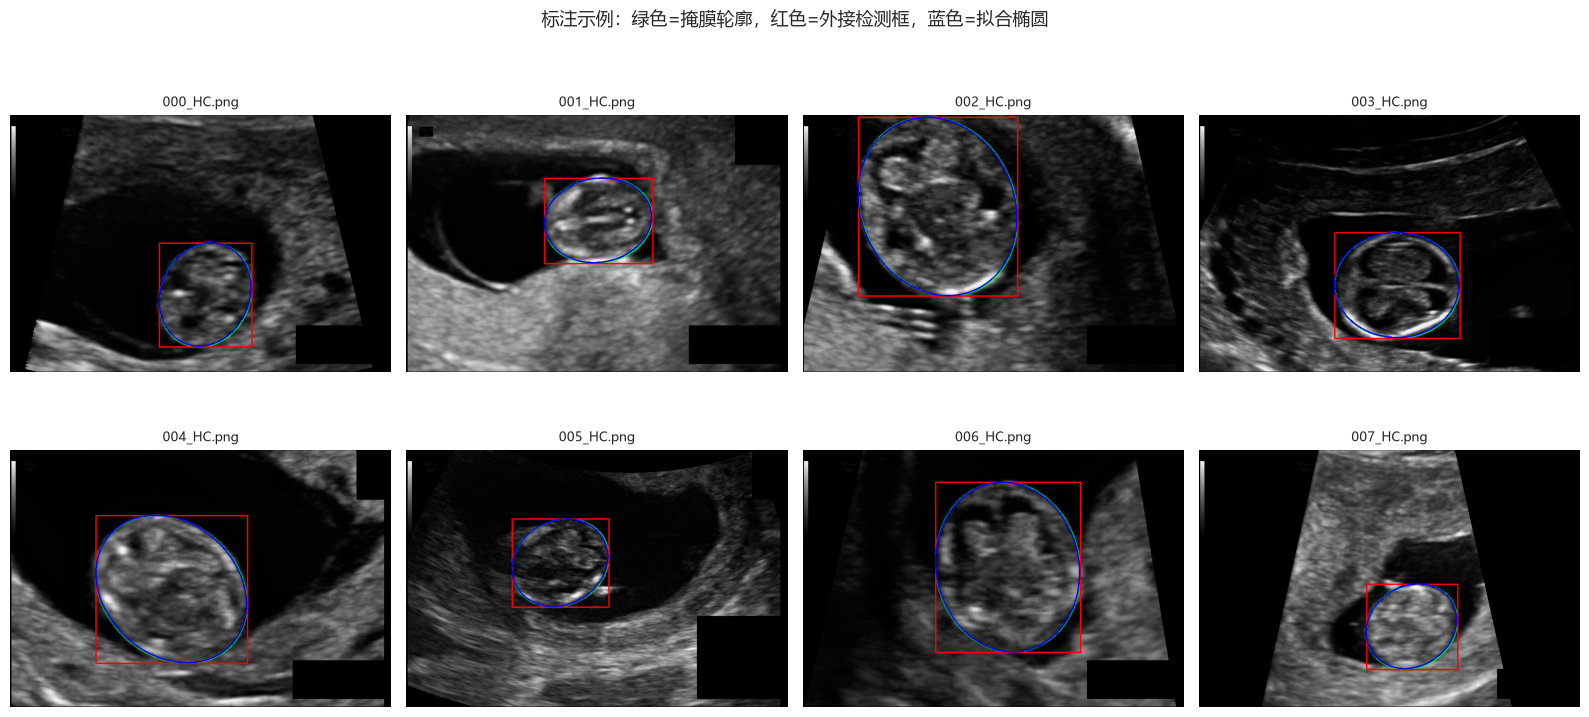

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i, ax in enumerate(axes.ravel()):
    img_i, mask_i, (xx1, yy1, xx2, yy2), (ccx, ccy, aa, bb, ang), cnt_i = annotate_one(train_imgs[i], train_masks[i])
    disp = cv2.cvtColor(img_i, cv2.COLOR_GRAY2BGR)
    cv2.drawContours(disp, [cnt_i], -1, (0, 255, 0), 2)
    cv2.rectangle(disp, (xx1, yy1), (xx2, yy2), (0, 0, 255), 2)
    cv2.ellipse(disp, (int(ccx), int(ccy)), (int(aa), int(bb)), ang, 0, 360, (255, 0, 0), 2)
    ax.imshow(cv2.cvtColor(disp, cv2.COLOR_BGR2RGB))
    ax.set_title(os.path.basename(train_imgs[i]), fontsize=9)
    ax.axis('off')
plt.suptitle('标注示例：绿色=掩膜轮廓，红色=外接检测框，蓝色=拟合椭圆', fontsize=13)
plt.tight_layout()
plt.show()

## 3. 数据分布统计

统计全部训练样本的检测框尺寸与头围分布，了解目标尺度变化。

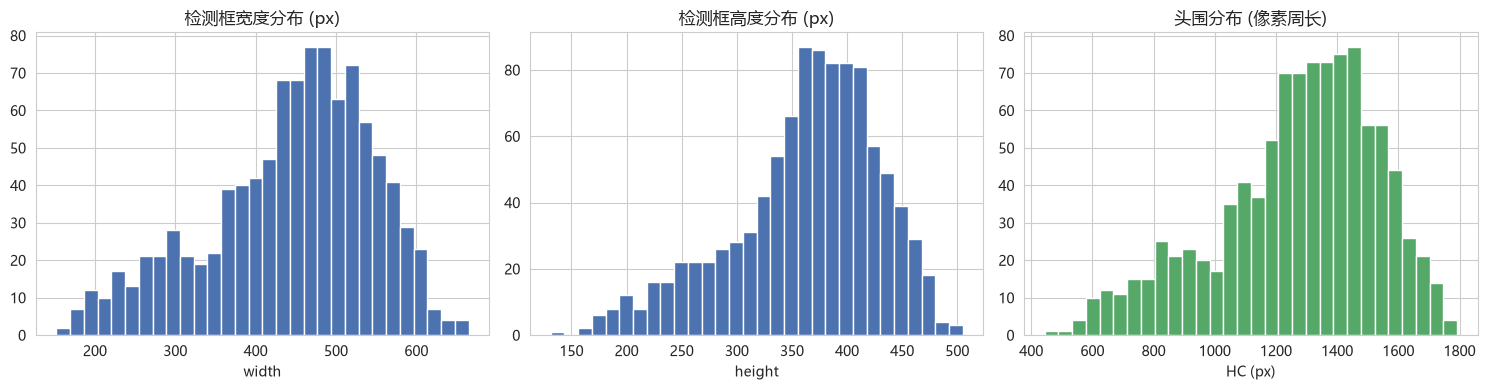

,w,h,hc_px
count,999.000000,999.000000,999.000000
mean,443.709710,362.249249,1268.491048
std,103.125591,67.603605,264.558855
min,152.000000,131.000000,444.205315
25%,383.500000,327.000000,1115.948130
50%,460.000000,372.000000,1310.784716
75%,519.000000,410.000000,1458.424315
max,665.000000,505.000000,1791.626838


In [5]:
rows = []
for img_path, mask_path in zip(train_imgs, train_masks):
    mask_i = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)
    binary = (mask_i > 0).astype(np.uint8)
    cnts, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cnt = max(cnts, key=cv2.contourArea)
    _, _, w, h = cv2.boundingRect(cnt)
    (_, _), (major, minor), _ = cv2.fitEllipse(cnt)
    rows.append({'w': w, 'h': h, 'hc_px': ellipse_circumference(major / 2.0, minor / 2.0)})
df_stats = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(df_stats['w'], bins=30, color='#4C72B0')
axes[0].set_title('检测框宽度分布 (px)')
axes[0].set_xlabel('width')
axes[1].hist(df_stats['h'], bins=30, color='#4C72B0')
axes[1].set_title('检测框高度分布 (px)')
axes[1].set_xlabel('height')
axes[2].hist(df_stats['hc_px'], bins=30, color='#55A868')
axes[2].set_title('头围分布 (像素周长)')
axes[2].set_xlabel('HC (px)')
plt.tight_layout()
plt.show()

df_stats.describe()

## 4. 数据预处理：掩膜 → YOLO 格式

`scripts/prepare_data.py` 完成以下转换：

- 灰度图复制为 3 通道，写入 `data/yolo/images/{train,val}/`；
- 掩膜轮廓的外接矩形 → YOLO 标签，格式为 `class x_center y_center width height`（归一化坐标）；
- 按病人划分训练 / 验证集（默认 8:2），同一病人的多张图不会跨集；
- 合并官方像素尺寸与头围真值（mm）到 `data/hc_ground_truth.csv`。

其中 `class=0` 表示胎头，其余为相对图像宽高的归一化值。

In [6]:
label_file = YOLO_DIR / 'labels' / 'train' / (os.path.basename(train_imgs[0]).replace('.png', '.txt'))
print('示例 YOLO 标签文件:', label_file)
if label_file.exists():
    print(label_file.read_text().strip())
else:
    print('(尚未生成，请先运行 scripts/prepare_data.py)')

yaml_file = ROOT / 'data' / 'dataset.yaml'
print()
print('--- dataset.yaml ---')
if yaml_file.exists():
    print(yaml_file.read_text())
else:
    print('(尚未生成 dataset.yaml)')

示例 YOLO 标签文件: E:\jerome\MyCode\HC18_YOLO\data\yolo\labels\train\000_HC.txt
0 0.512500 0.700000 0.242500 0.403704

--- dataset.yaml ---
path: E:/jerome/MyCode/HC18/data
train: yolo/images/train
val: yolo/images/val
names:
  0: fetal_head



## 5. 训练过程回顾

下面自动查找 `runs/detect/` 下的训练日志，绘制损失与 mAP 曲线。若尚未训练，会给出提示。

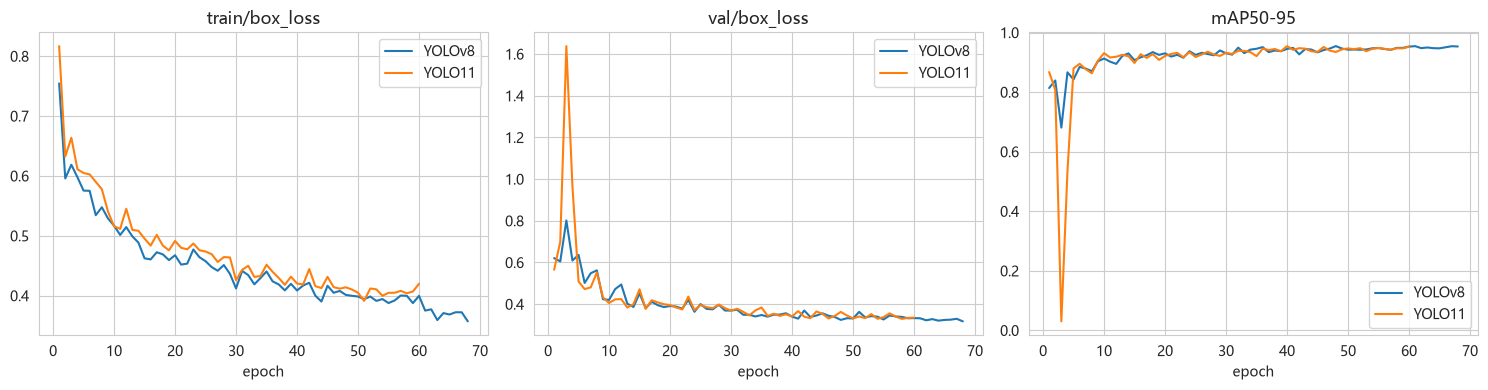

In [7]:
def find_results(name):
    hits = sorted(RUNS_DIR.glob(f'detect/{name}*/results.csv'))
    return hits[-1] if hits else None

v8_csv = find_results('yolov8')
v11_csv = find_results('yolo11')

if v8_csv and v11_csv:
    r8 = pd.read_csv(v8_csv)
    r11 = pd.read_csv(v11_csv)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].plot(r8['epoch'], r8['train/box_loss'], label='YOLOv8')
    axes[0].plot(r11['epoch'], r11['train/box_loss'], label='YOLO11')
    axes[0].set_title('train/box_loss')
    axes[0].set_xlabel('epoch')
    axes[0].legend()
    axes[1].plot(r8['epoch'], r8['val/box_loss'], label='YOLOv8')
    axes[1].plot(r11['epoch'], r11['val/box_loss'], label='YOLO11')
    axes[1].set_title('val/box_loss')
    axes[1].set_xlabel('epoch')
    axes[1].legend()
    axes[2].plot(r8['epoch'], r8['metrics/mAP50-95(B)'], label='YOLOv8')
    axes[2].plot(r11['epoch'], r11['metrics/mAP50-95(B)'], label='YOLO11')
    axes[2].set_title('mAP50-95')
    axes[2].set_xlabel('epoch')
    axes[2].legend()
    plt.tight_layout()
    plt.show()
else:
    print('未找到训练结果，请先运行 scripts/train.py 训练两个模型。')

## 6. 结果可视化：导入训练好的权重

加载训练得到的 `best.pt`，在验证集图像上运行推理，画出检测框、拟合椭圆并计算头围（乘以像素尺寸换算为毫米），同时对比 YOLOv8 与 YOLO11 的预测结果。

In [8]:
try:
    from ultralytics import YOLO
    ULTRALYTICS_OK = True
except ImportError:
    ULTRALYTICS_OK = False
    print('未安装 ultralytics，请先执行: pip install -r requirements.txt')


def find_best(name):
    hits = sorted(RUNS_DIR.glob(f'detect/{name}*/weights/best.pt'))
    return hits[-1] if hits else None


def draw_pred(img, result, px_size=None):
    disp = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR) if img.ndim == 2 else img.copy()
    if result.boxes is None or len(result.boxes) == 0:
        return disp, None
    conf = result.boxes.conf.cpu().numpy()
    xyxy = result.boxes.xyxy.cpu().numpy()
    k = int(np.argmax(conf))
    x1, y1, x2, y2 = xyxy[k]
    cx, cy = (x1 + x2) / 2.0, (y1 + y2) / 2.0
    a, b = (x2 - x1) / 2.0, (y2 - y1) / 2.0
    hc = ellipse_circumference(a, b)
    cv2.rectangle(disp, (int(x1), int(y1)), (int(x2), int(y2)), (0, 0, 255), 2)
    cv2.ellipse(disp, (int(cx), int(cy)), (int(a), int(b)), 0, 0, 360, (255, 0, 0), 2)
    if px_size is not None:
        txt = f'HC={hc * px_size:.1f}mm  conf={conf[k]:.2f}'
    else:
        txt = f'HC={hc:.1f}px  conf={conf[k]:.2f}'
    cv2.putText(disp, txt, (int(x1), int(y1) - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 1)
    return disp, hc

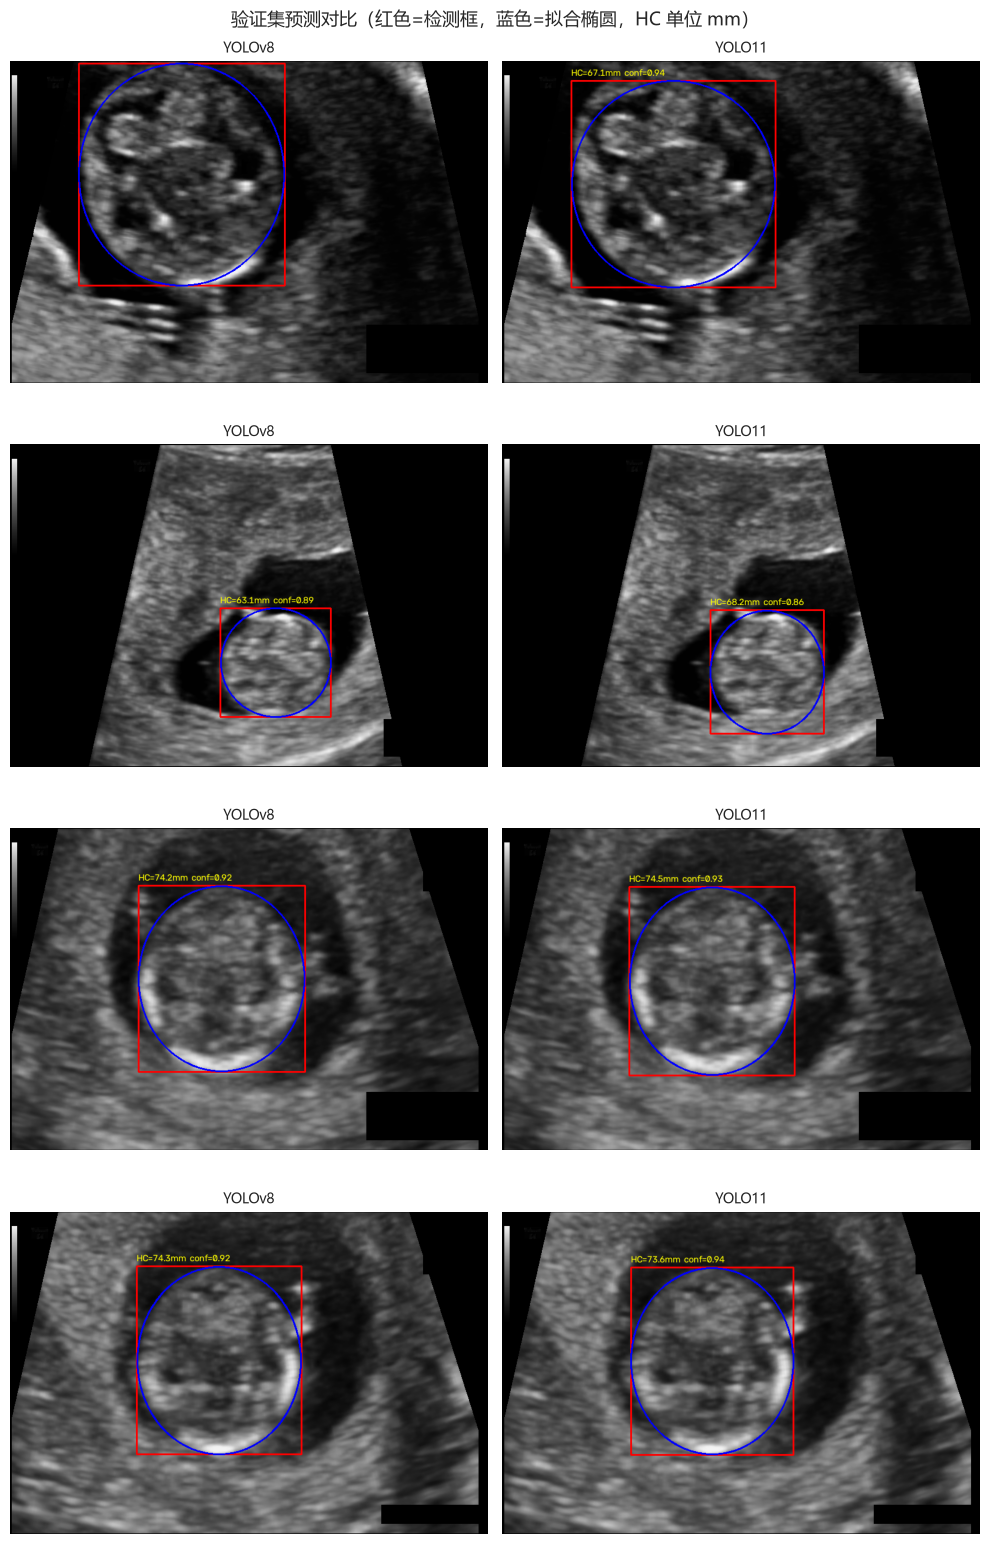

In [9]:
v8_best = find_best('yolov8')
v11_best = find_best('yolo11')
val_imgs = sorted((YOLO_DIR / 'images' / 'val').glob('*.png'))
px_map = dict(zip(px_train['filename'], px_train['pixel_size_mm']))

if ULTRALYTICS_OK and v8_best and v11_best and val_imgs:
    model8 = YOLO(str(v8_best))
    model11 = YOLO(str(v11_best))
    demo = val_imgs[:4]
    fig, axes = plt.subplots(len(demo), 2, figsize=(10, 4 * len(demo)))
    for i, p in enumerate(demo):
        img_i = cv2.imread(str(p), cv2.IMREAD_UNCHANGED)
        px_size = px_map.get(p.name, None)
        res8 = model8.predict(str(p), imgsz=640, verbose=False)[0]
        res11 = model11.predict(str(p), imgsz=640, verbose=False)[0]
        d8, _ = draw_pred(img_i, res8, px_size)
        d11, _ = draw_pred(img_i, res11, px_size)
        for ax, disp, title in zip(axes[i], [d8, d11], ['YOLOv8', 'YOLO11']):
            ax.imshow(cv2.cvtColor(disp, cv2.COLOR_BGR2RGB))
            ax.set_title(title, fontsize=10)
            ax.axis('off')
    plt.suptitle('验证集预测对比（红色=检测框，蓝色=拟合椭圆，HC 单位 mm）', fontsize=13)
    plt.tight_layout()
    plt.show()
else:
    print('请先运行训练得到 best.pt（或检查 ultralytics 是否安装）。')

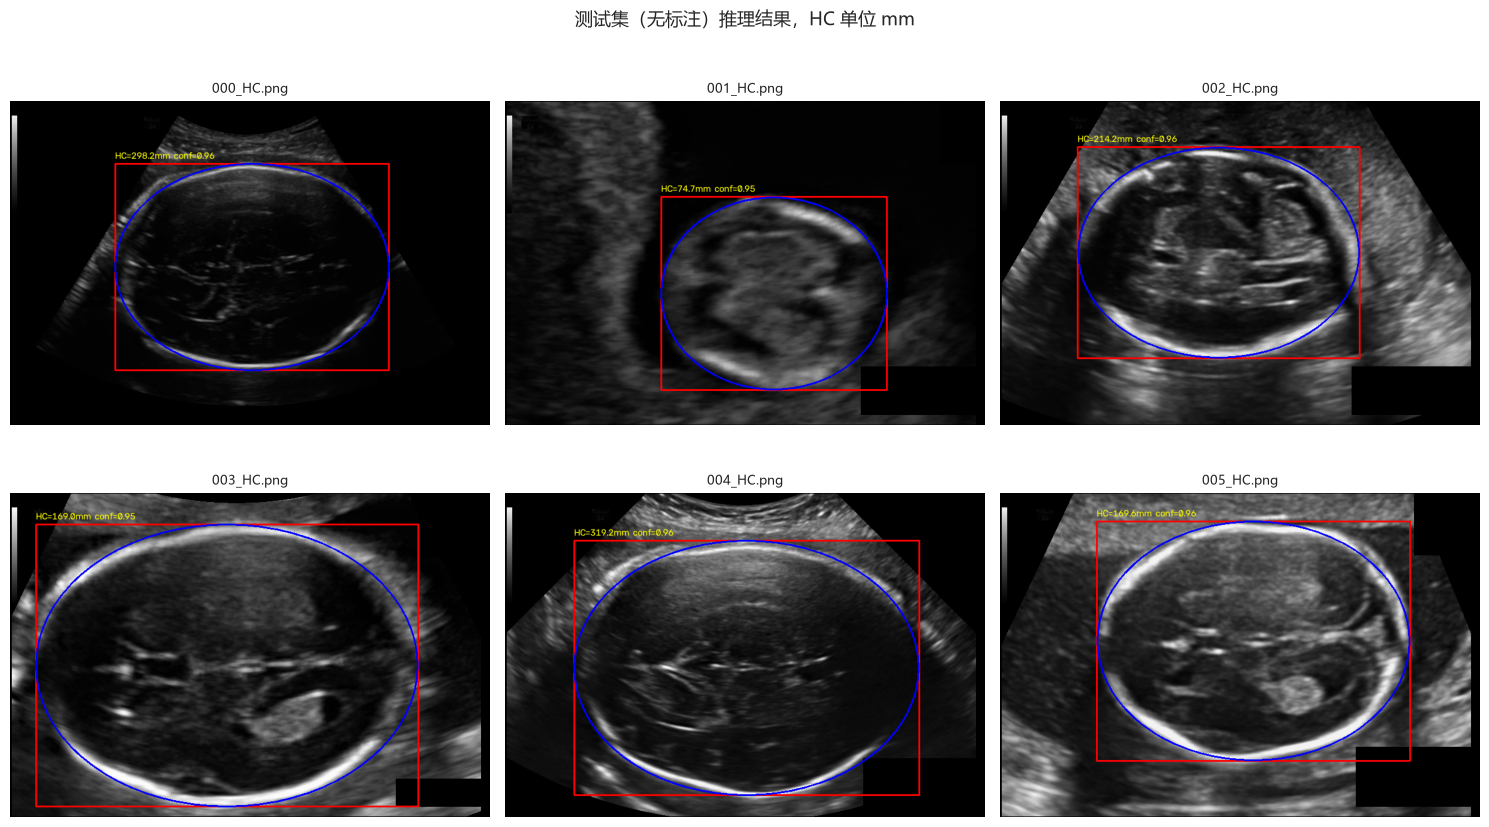

In [10]:
if ULTRALYTICS_OK and (v11_best or v8_best):
    use_best = v11_best or v8_best
    model = YOLO(str(use_best))
    px_test_map = dict(zip(px_test['filename'], px_test['pixel_size_mm']))
    demo_test = test_imgs[:6]
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    for ax, p in zip(axes.ravel(), demo_test):
        img_i = cv2.imread(p, cv2.IMREAD_UNCHANGED)
        res = model.predict(p, imgsz=640, verbose=False)[0]
        disp, _ = draw_pred(img_i, res, px_test_map.get(os.path.basename(p), None))
        ax.imshow(cv2.cvtColor(disp, cv2.COLOR_BGR2RGB))
        ax.set_title(os.path.basename(p), fontsize=9)
        ax.axis('off')
    plt.suptitle('测试集（无标注）推理结果，HC 单位 mm', fontsize=13)
    plt.tight_layout()
    plt.show()
else:
    print('请先训练得到 best.pt。')

## 7. 性能对比

`scripts/compare.py` 会输出两个模型的检测指标（mAP 等）与头围估计误差（MAD，单位 mm）。若已运行，这里直接读取结果可视化。

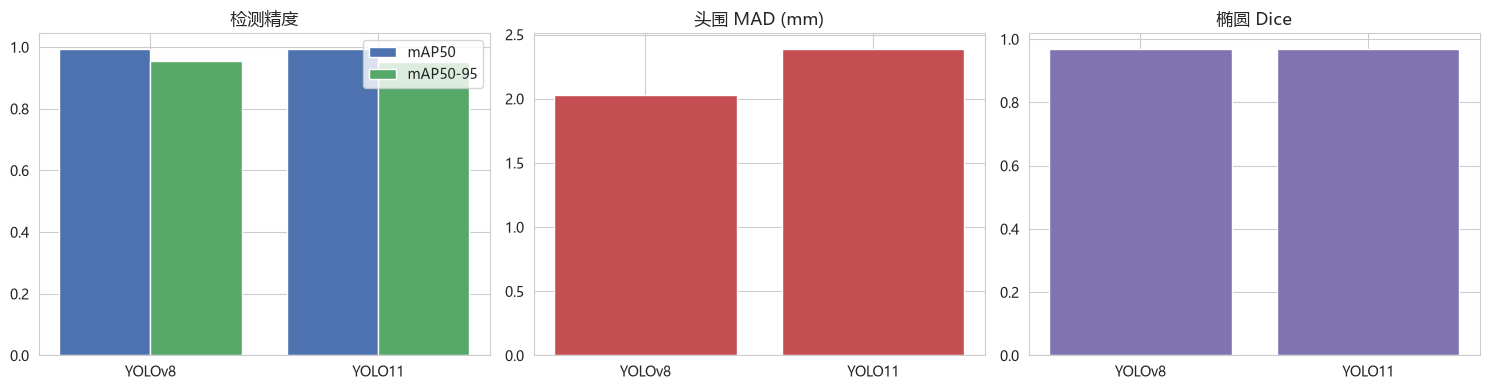

In [11]:
comp_csv = RUNS_DIR / 'comparison' / 'comparison_metrics.csv'
if comp_csv.exists():
    comp = pd.read_csv(comp_csv)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    names = comp['model'].tolist()
    x = np.arange(len(names))
    axes[0].bar(x - 0.2, comp['mAP50'], 0.4, label='mAP50', color='#4C72B0')
    axes[0].bar(x + 0.2, comp['mAP50-95'], 0.4, label='mAP50-95', color='#55A868')
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(names)
    axes[0].set_title('检测精度')
    axes[0].legend()
    axes[1].bar(names, comp['MAD_mm'], color='#C44E52')
    axes[1].set_title('头围 MAD (mm)')
    axes[2].bar(names, comp['DSC'], color='#8172B2')
    axes[2].set_title('椭圆 Dice')
    plt.tight_layout()
    plt.show()
    comp.round(4)
else:
    print('请先运行 scripts/compare.py 生成对比结果。')

## 8. 结论

- 检测精度方面，YOLO11 在相同规模下通常略优于 YOLOv8（更高的 mAP、更少的参数）；
- 头围估计方面，以 MAD（mm）与 Dice 衡量，两者均能较准确地定位胎头椭圆；
- 实际选择还需结合推理速度与部署平台权衡。

（以上为一般性结论，具体以本项目训练输出 `runs/comparison/comparison_metrics.csv` 为准。）